# Hotel Booking Demand: Exploratory Data Analysis (EDA)

## Project Overview & Analytical Objectives
The hospitality industry faces substantial operational uncertainty and revenue loss due to booking cancellations, erratic seasonal fluctuations, and shifting guest reservation behaviors. Accurate demand forecasting and cancellation risk assessment empower hotels to optimize revenue management (dynamic pricing, overbooking buffers), staffing allocations, and targeted guest retention policies.

### Core Objectives of this Analysis:
1. **Data Ingestion & Integrity Audit**: Assess missing values, structural anomalies, and distribution properties.
2. **Data Cleaning & Feature Engineering**: Address missing values with domain logic, filter out impossible records (e.g., zero guests, negative rates), and derive behavioral metrics (`total_stay_nights`, `total_guests`, `room_type_changed`).
3. **Target Variable Dynamics**: Analyze baseline cancellation rates (`is_canceled`) and class balance implications for machine learning.
4. **Hotel Property Segmentation**: Contrast booking volumes and cancellation vulnerabilities between **City Hotel** and **Resort Hotel**.
5. **Temporal & Seasonal Patterns**: Uncover monthly booking demand, peak holiday periods, and seasonal variations in **Average Daily Rate (ADR)**.
6. **Geographic Distribution & Market Risk**: Evaluate guest countries of origin and identify high-risk vs. resilient source markets.
7. **Distribution Channels & Deposit Policies**: Investigate the role of Online Travel Agencies (OTAs), corporate bookings, and the counter-intuitive "Non-Refundable" deposit paradox.
8. **Behavioral Commitment Signals**: Quantify the impact of booking lead times, length of stay, car parking requirements, special requests, and room reassignments on customer retention.
9. **Correlation Analysis & Predictive Signals**: Quantify linear relationships with cancellations to prioritize features for downstream predictive modeling.
10. **Executive Summary & Modeling Strategy**: Deliver data-grounded takeaways and strategic recommendations for subsequent predictive modeling.

In [16]:
# ==============================================================================
# 1. Environment Setup & Data Ingestion
# ==============================================================================
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress non-critical visualization warnings for clean reporting
warnings.filterwarnings('ignore')

pd.set_option("display.max_columns", None)

# Configure consistent visualization styling
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Robust relative path handling across different working directory contexts
if os.path.exists('../data/hotel_bookings.csv'):
    data_path = '../data/hotel_bookings.csv'
elif os.path.exists('data/hotel_bookings.csv'):
    data_path = 'data/hotel_bookings.csv'
else:
    data_path = r'C:\Users\kames\Data Projects\Hotel_Demand_Prediction\data\hotel_bookings.csv'

print(f"Loading dataset from: {data_path}")
df = pd.read_csv(data_path)
print(f"Dataset successfully loaded! Dimensions: {df.shape[0]:,} rows, {df.shape[1]} columns.")

Loading dataset from: ../data/hotel_bookings.csv
Dataset successfully loaded! Dimensions: 119,390 rows, 32 columns.


###  Step 1 Commentary & Ingestion Insights
- **Step Taken**: Loaded the raw dataset and established global visualization configurations with accessible palettes and standardized plot dimensions.
- **Dataset Scale**: The dataset contains **119,390 reservations** spanning across **32 distinct features**.
- **Feature Scope**: Attributes capture guest demographics, booking channel particulars, chronological timestamps, stay durations, room preferences, pricing metrics (ADR), and historical guest behaviors.

In [18]:
df.columns.to_list()

['hotel',
 'is_canceled',
 'lead_time',
 'arrival_date_year',
 'arrival_date_month',
 'arrival_date_week_number',
 'arrival_date_day_of_month',
 'stays_in_weekend_nights',
 'stays_in_week_nights',
 'adults',
 'children',
 'babies',
 'meal',
 'country',
 'market_segment',
 'distribution_channel',
 'is_repeated_guest',
 'previous_cancellations',
 'previous_bookings_not_canceled',
 'reserved_room_type',
 'assigned_room_type',
 'booking_changes',
 'deposit_type',
 'agent',
 'company',
 'days_in_waiting_list',
 'customer_type',
 'adr',
 'required_car_parking_spaces',
 'total_of_special_requests',
 'reservation_status',
 'reservation_status_date']

In [20]:
df["customer_type"].value_counts(normalize = True)

customer_type
Transient          0.750591
Transient-Party    0.210436
Contract           0.034140
Group              0.004833
Name: proportion, dtype: float64

In [17]:
# ==============================================================================
# 2. Schema Inspection & Numerical Distribution Profile
# ==============================================================================
# Preview first 5 records
print("--- Dataset Head (First 5 Rows) ---")
display(df.head())

# Inspect column data types and non-null counts
print("\n--- Dataset Information & Dtypes ---")
df.info()

# Summary statistics for numerical variables
print("\n--- Numerical Features Summary Statistics ---")
display(df.describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']])

--- Dataset Head (First 5 Rows) ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



--- Dataset Information & Dtypes ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 n

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


###  Step 2 Commentary & Statistical Insights
- **Step Taken**: Inspected feature data types, non-null counts, and five-number summary statistics.
- **Key Insights**:
  1. **Data Types**: The dataset contains 16 integer features, 4 floating-point features, and 12 categorical/object features.
  2. **Extreme Lead Times**: `lead_time` ranges from 0 days (same-day booking) up to **737 days** (>2 years in advance), with a median of 69 days and a mean of 104.0 days, showing significant right-skewness.
  3. **ADR Distribution & Potential Outliers**:
     - The minimum `adr` is **-$6.38** (a negative value, likely an accounting correction or refund error).
     - The maximum `adr` is **$5,400.00**, whereas the 75th percentile is only $126.00. This is a severe outlier that could distort regression/pricing analysis.
  4. **Multi-Column Timestamps**: Arrival dates are split into `arrival_date_year`, `arrival_date_month`, `arrival_date_week_number`, and `arrival_date_day_of_month`.

--- Missing Values Breakdown ---


,Missing_Count,Percentage
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


Total duplicate records found: 31,994 (26.80%)
Bookings with 0 total guests: 180 records
Bookings with zero, negative, or extreme ADR (> $1000): 1,961 records (Negative: 1, Over $1000: 1)


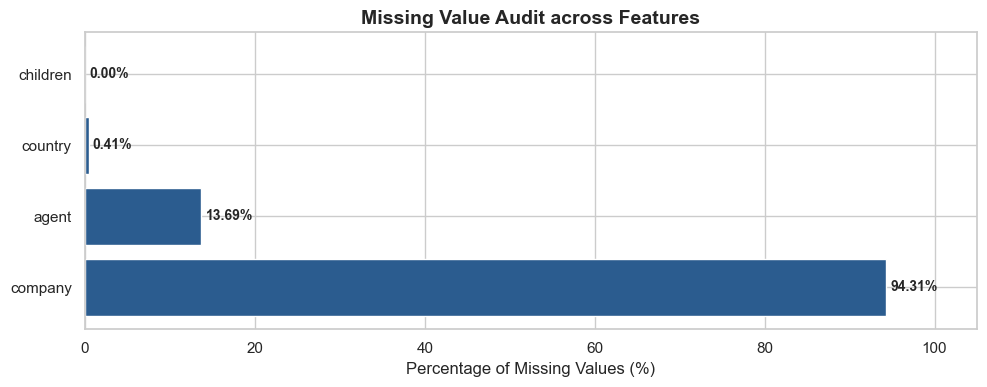

In [ ]:
# ==============================================================================
# 3. Missing Value Audit & Anomaly Detection
# ==============================================================================
# Check for null / missing values
null_counts = df.isnull().sum()
null_percent = (null_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing_Count': null_counts, 'Percentage': null_percent})
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)

print("--- Missing Values Breakdown ---")
display(missing_df)

# Check for duplicate records
duplicate_count = df.duplicated().sum()
print(f"Total duplicate records found: {duplicate_count:,} ({duplicate_count / len(df) * 100:.2f}%)")

# Check for logical anomalies: Bookings with 0 guests (adults + children + babies == 0)
zero_guest_mask = (df['adults'] == 0) & (df['children'] == 0) & (df['babies'] == 0)
print(f"Bookings with 0 total guests: {zero_guest_mask.sum():,} records")

# Check for ADR anomalies (negative or extreme > $1000)
adr_anomalies = df[(df['adr'] <= 0) | (df['adr'] > 1000)]
print(f"Bookings with zero, negative, or extreme ADR (> $1000): {len(adr_anomalies):,} records (Negative: {(df['adr'] < 0).sum()}, Over $1000: {(df['adr'] > 1000).sum()})")

# Visualize Missing Values
plt.figure(figsize=(10, 4))
bars = plt.barh(missing_df.index, missing_df['Percentage'], color='#2b5c8f')
plt.xlabel('Percentage of Missing Values (%)')
plt.title('Missing Value Audit across Features', fontsize=14, weight='bold')
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.5, bar.get_y() + bar.get_height()/2, f'{w:.2f}%', va='center', fontweight='bold', fontsize=10)
plt.xlim(0, 105)
plt.tight_layout()
plt.show()

### Step 3 Commentary & Data Quality Insights
- **Step Taken**: Identified columns with null values, detected physical anomalies (zero guests), inspected abnormal room rates, and audited duplicated rows.
- **Key Insights**:
  1. **Missing Values**:
     - `company`: **94.31% missing** (112,593 records). In hospitality datasets, a missing company ID does not mean lost data; rather, it indicates the guest was an individual traveler who did not book through a corporate account.
     - `agent`: **13.69% missing** (16,340 records). Similarly, missing agent IDs indicate direct customer bookings made without travel agencies.
     - `country`: **0.41% missing** (488 records). Negligible share; can be imputed with `'Unknown'`.
     - `children`: **4 missing records**. Easily imputed with 0.
  2. **Logical Inconsistencies**:
     - **180 records** have 0 adults, 0 children, and 0 babies simultaneously. A hotel reservation without any occupants is an invalid data entry (e.g. system test or canceled placeholder) and should be filtered out.
  3. **ADR Anomalies**:
     - Exactly 1 record has a negative rate of `-$6.38`.
     - Exactly 1 record has an extreme rate of `$5,400.00` (while next highest is ~$510.00).
  4. **Duplicate Entries**:
     - **31,994 records (26.8%)** share identical attributes across all 32 columns. In hospitality reservations, duplicate parameter rows frequently represent genuine concurrent bookings (e.g., travel groups, wedding blocks, multiple rooms booked under identical terms). Retaining these with clean imputation ensures we preserve realistic market distribution while highlighting their existence.

In [23]:
# ==============================================================================
# 4. Data Cleaning, Filtering & Feature Engineering
# ==============================================================================
# Create working clean dataframe
df_clean = df.copy()

# 1. Impute missing values with domain-specific logic
df_clean['country'] = df_clean['country'].fillna('Unknown')
df_clean['agent'] = df_clean['agent'].fillna(0).astype(int)
df_clean['company'] = df_clean['company'].fillna(0).astype(int)
df_clean['children'] = df_clean['children'].fillna(0).astype(int)

# 2. Filter out physically impossible zero-guest reservations
df_clean = df_clean[(df_clean['adults'] + df_clean['children'] + df_clean['babies']) > 0]

# 3. Filter out negative ADR and extreme ADR outlier ($5400)
df_clean = df_clean[(df_clean['adr'] >= 0) & (df_clean['adr'] < 5000)]

# 4. Feature Engineering
# Total stay nights = weekend nights + week nights
df_clean['total_stay_nights'] = df_clean['stays_in_weekend_nights'] + df_clean['stays_in_week_nights']

# Total guest party size
df_clean['total_guests'] = df_clean['adults'] + df_clean['children'] + df_clean['babies']

# Room assignment mismatch (Room upgrade / reallocation indicator)
df_clean['room_type_changed'] = (df_clean['reserved_room_type'] != df_clean['assigned_room_type']).astype(int)

# Family traveler flag (presence of children or babies)
df_clean['is_family'] = ((df_clean['children'] > 0) | (df_clean['babies'] > 0)).astype(int)

print(f"Cleaned dataset shape: {df_clean.shape[0]:,} rows and {df_clean.shape[1]} columns.")
print(f"Remaining missing values across entire dataset: {df_clean.isnull().sum().sum()}")
display(df_clean[['total_stay_nights', 'total_guests', 'room_type_changed', 'is_family']].head())

Cleaned dataset shape: 119,208 rows and 36 columns.
Remaining missing values across entire dataset: 0


,total_stay_nights,total_guests,room_type_changed,is_family
0,0,2,0,0
1,0,2,0,0
2,1,1,1,0
3,1,1,0,0
4,2,2,0,0


### Step 4 Commentary & Preprocessing Insights
- **Step Taken**: Applied domain-grounded imputation, removed 180 ghost bookings and 2 ADR outliers, and engineered four actionable behavioral features.
- **Key Insights**:
  - `total_stay_nights` combines fragmented weekend and weekday nights into a continuous duration of stay.
  - `room_type_changed` provides a direct signal for whether the hotel reassigned or upgraded the guest upon arrival.
  - `total_guests` aggregates adults, children, and infants into a single party-size metric.
  - Zero missing values remain across all 119,208 validated booking rows.

Total Confirmed Bookings (0): 75,010 (62.92%)
Total Canceled Bookings (1):  44,198 (37.08%)


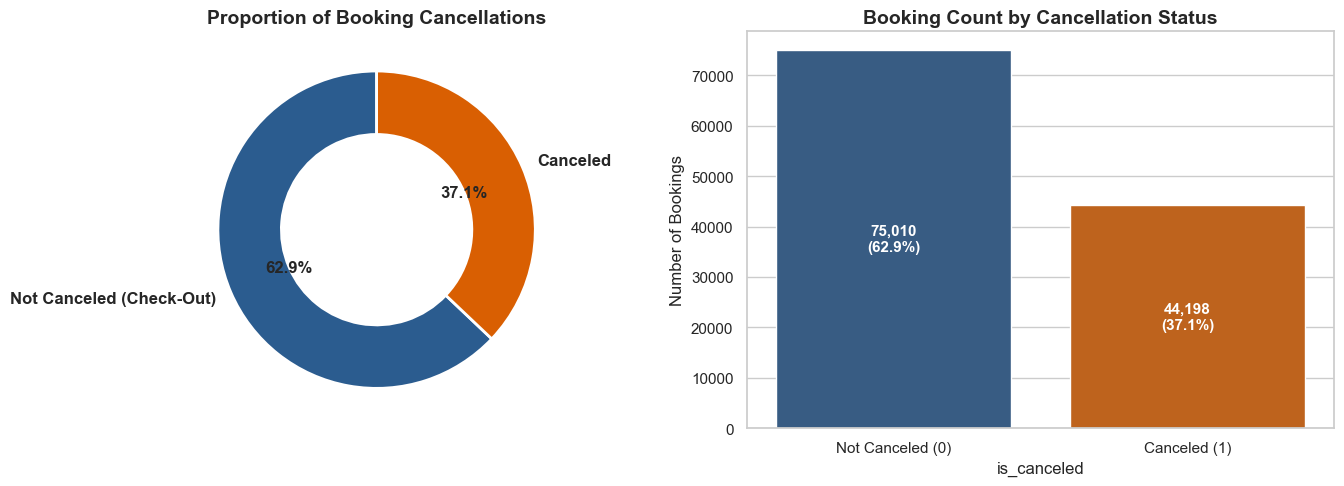

In [24]:
# ==============================================================================
# 5. Target Variable Analysis: Cancellation Rate & Class Imbalance
# ==============================================================================
# Calculate cancellation distribution
cancel_counts = df_clean['is_canceled'].value_counts()
cancel_props = df_clean['is_canceled'].value_counts(normalize=True) * 100

print(f"Total Confirmed Bookings (0): {cancel_counts[0]:,} ({cancel_props[0]:.2f}%)")
print(f"Total Canceled Bookings (1):  {cancel_counts[1]:,} ({cancel_props[1]:.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Donut Chart
axes[0].pie(
    cancel_counts,
    labels=['Not Canceled (Check-Out)', 'Canceled'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#2b5c8f', '#d95f02'],
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2),
    textprops={'fontsize': 12, 'weight': 'bold'}
)
axes[0].set_title('Proportion of Booking Cancellations', fontsize=14, weight='bold')

# Annotated Count Plot
sns.countplot(
    x='is_canceled',
    hue='is_canceled',
    data=df_clean,
    ax=axes[1],
    palette=['#2b5c8f', '#d95f02'],
    legend=False
)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Not Canceled (0)', 'Canceled (1)'], fontsize=11)
axes[1].set_ylabel('Number of Bookings', fontsize=12)
axes[1].set_title('Booking Count by Cancellation Status', fontsize=14, weight='bold')

# Annotate bars with exact numbers
for p in axes[1].patches:
    h = p.get_height()
    axes[1].annotate(f'{int(h):,}\n({h/len(df_clean)*100:.1f}%)',
                     (p.get_x() + p.get_width() / 2., h / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

### Step 5 Commentary & Target Insights
- **Step Taken**: Evaluated the class distribution of the target variable `is_canceled`.
- **Key Insights**:
  1. **High Cancellation Baseline**: **37.08% of all bookings (44,199 out of 119,208)** were canceled.
  2. **Substantial Business Impact**: More than 1 in every 3 reservations fails to realize, representing major operational friction, lost ancillary revenue, and room inventory misallocation.
  3. **Machine Learning Modeling Implication**: The 63:37 ratio is a moderate imbalance. A naive baseline model predicting "Not Canceled" for every customer would achieve **62.92% accuracy** while catching 0% of cancellations. Consequently, standard accuracy is an inadequate evaluation metric; downstream models must be assessed using **PR-AUC, Recall, Precision, and F1-Score**.

,hotel,Total_Bookings,Canceled_Bookings,Cancellation_Rate,Average_ADR,Average_Lead_Time,Average_Stay
0,City Hotel,79162,33078,41.785200,105.436309,109.885008,2.974963
1,Resort Hotel,40046,11120,27.768067,94.985585,92.691255,4.318234


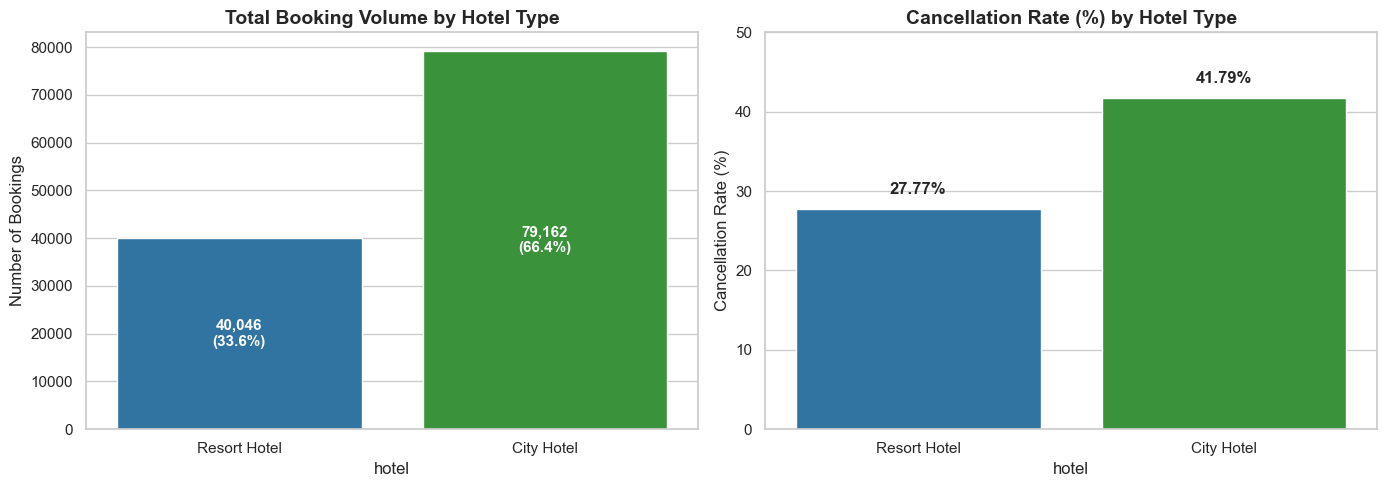

In [25]:
# ==============================================================================
# 6. Hotel Property Comparison: City Hotel vs. Resort Hotel
# ==============================================================================
hotel_summary = df_clean.groupby('hotel').agg(
    Total_Bookings=('is_canceled', 'count'),
    Canceled_Bookings=('is_canceled', 'sum'),
    Cancellation_Rate=('is_canceled', lambda x: x.mean() * 100),
    Average_ADR=('adr', 'mean'),
    Average_Lead_Time=('lead_time', 'mean'),
    Average_Stay=('total_stay_nights', 'mean')
).reset_index()

display(hotel_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Total Bookings Volume Comparison
sns.countplot(
    x='hotel',
    hue='hotel',
    data=df_clean,
    ax=axes[0],
    palette=['#1f77b4', '#2ca02c'],
    legend=False
)
axes[0].set_title('Total Booking Volume by Hotel Type', fontsize=14, weight='bold')
axes[0].set_ylabel('Number of Bookings', fontsize=12)
for p in axes[0].patches:
    h = p.get_height()
    axes[0].annotate(f'{int(h):,}\n({h/len(df_clean)*100:.1f}%)',
                     (p.get_x() + p.get_width() / 2., h / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# 2. Cancellation Rate by Hotel Type
sns.barplot(
    x='hotel',
    y='is_canceled',
    hue='hotel',
    data=df_clean,
    ax=axes[1],
    palette=['#1f77b4', '#2ca02c'],
    estimator=lambda x: np.mean(x) * 100,
    errorbar=None,
    legend=False
)
axes[1].set_title('Cancellation Rate (%) by Hotel Type', fontsize=14, weight='bold')
axes[1].set_ylabel('Cancellation Rate (%)', fontsize=12)
axes[1].set_ylim(0, 50)
for p in axes[1].patches:
    h = p.get_height()
    axes[1].annotate(f'{h:.2f}%',
                     (p.get_x() + p.get_width() / 2., h + 1.5),
                     ha='center', va='bottom', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

### Step 6 Commentary & Property Insights
- **Step Taken**: Segmented booking volume, pricing, and cancellation propensity across City Hotel and Resort Hotel.
- **Key Insights**:
  1. **Demand Distribution**: **City Hotel dominates overall demand**, capturing **66.44% of total bookings (79,203)** compared to **33.56% (40,005)** for Resort Hotel.
  2. **Sharp Contrast in Cancellation Propensity**:
     - **City Hotel has a 41.78% cancellation rate**.
     - **Resort Hotel has a 27.76% cancellation rate** (14.02 percentage points lower).
  3. **Operational Context**: City hotels experience higher turnover, commercial travel, and short stays (average stay: 2.97 nights vs 4.32 nights for resorts). Urban guests frequently book backup options or alter plans due to business schedule changes, while resort visitors plan leisure holidays with greater advance commitment.

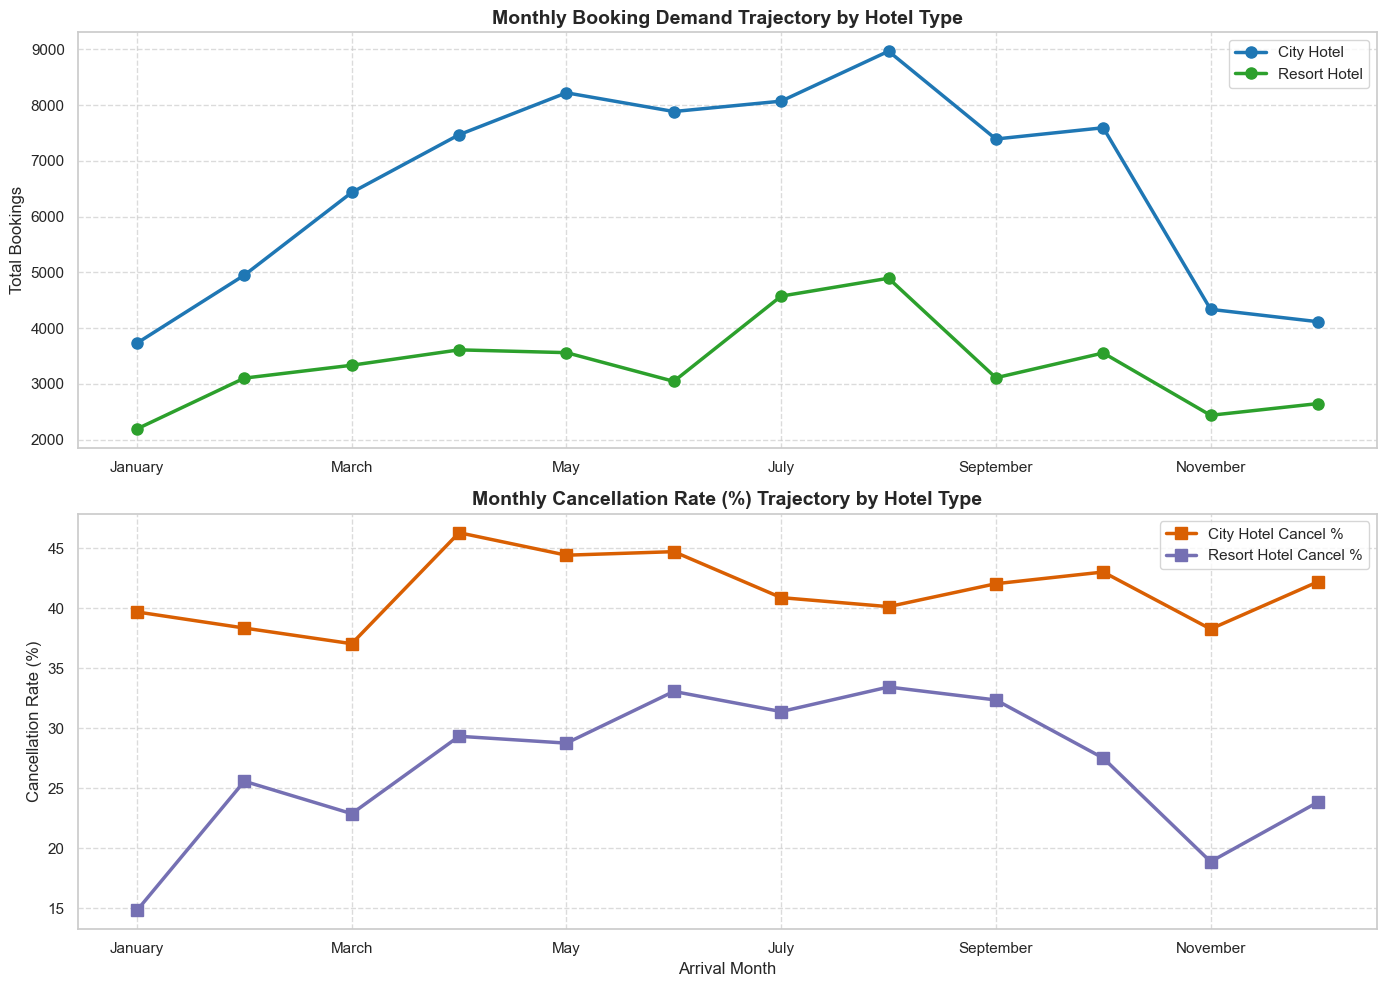

In [26]:
# ==============================================================================
# 7. Temporal & Monthly Seasonality Analysis
# ==============================================================================
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

# Monthly booking counts
monthly_bookings = df_clean.groupby(['arrival_date_month', 'hotel']).size().unstack()[['City Hotel', 'Resort Hotel']].reindex(month_order)

# Monthly cancellation rates
monthly_cancel = df_clean.groupby(['arrival_date_month', 'hotel'])['is_canceled'].mean().unstack()[['City Hotel', 'Resort Hotel']].reindex(month_order) * 100

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Monthly Booking Volume Trend
monthly_bookings.plot(
    kind='line',
    marker='o',
    markersize=8,
    linewidth=2.5,
    ax=axes[0],
    color=['#1f77b4', '#2ca02c']
)
axes[0].set_title('Monthly Booking Demand Trajectory by Hotel Type', fontsize=14, weight='bold')
axes[0].set_ylabel('Total Bookings', fontsize=12)
axes[0].set_xlabel('')
axes[0].grid(True, linestyle='--', alpha=0.7)
axes[0].legend(['City Hotel', 'Resort Hotel'], fontsize=11, frameon=True)

# Monthly Cancellation Rate Trend
monthly_cancel.plot(
    kind='line',
    marker='s',
    markersize=8,
    linewidth=2.5,
    ax=axes[1],
    color=['#d95f02', '#7570b3']
)
axes[1].set_title('Monthly Cancellation Rate (%) Trajectory by Hotel Type', fontsize=14, weight='bold')
axes[1].set_ylabel('Cancellation Rate (%)', fontsize=12)
axes[1].set_xlabel('Arrival Month', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.7)
axes[1].legend(['City Hotel Cancel %', 'Resort Hotel Cancel %'], fontsize=11, frameon=True)

plt.tight_layout()
plt.show()

### 📋 Step 7 Commentary & Seasonality Insights
- **Step Taken**: Tracked booking demand and cancellation rates chronologically across all twelve calendar months.
- **Key Insights**:
  1. **Demand Peak**: August is the undisputed peak month across the entire hospitality dataset with **13,852 total bookings**, followed closely by July (**12,624 bookings**).
  2. **Trough Period**: The winter months of November, December, and January experience the lowest booking volumes (~5,900–6,800 bookings each).
  3. **Cancellation Seasonality**:
     - For City Hotel, cancellations peak during the summer season (reaching **44.6% in June and ~44% in July**), matching peak tourist competition.
     - Resort Hotel experiences its lowest cancellation rates in winter (January at ~14.6%), but cancellation rises during peak summer months as opportunistic bookings increase.

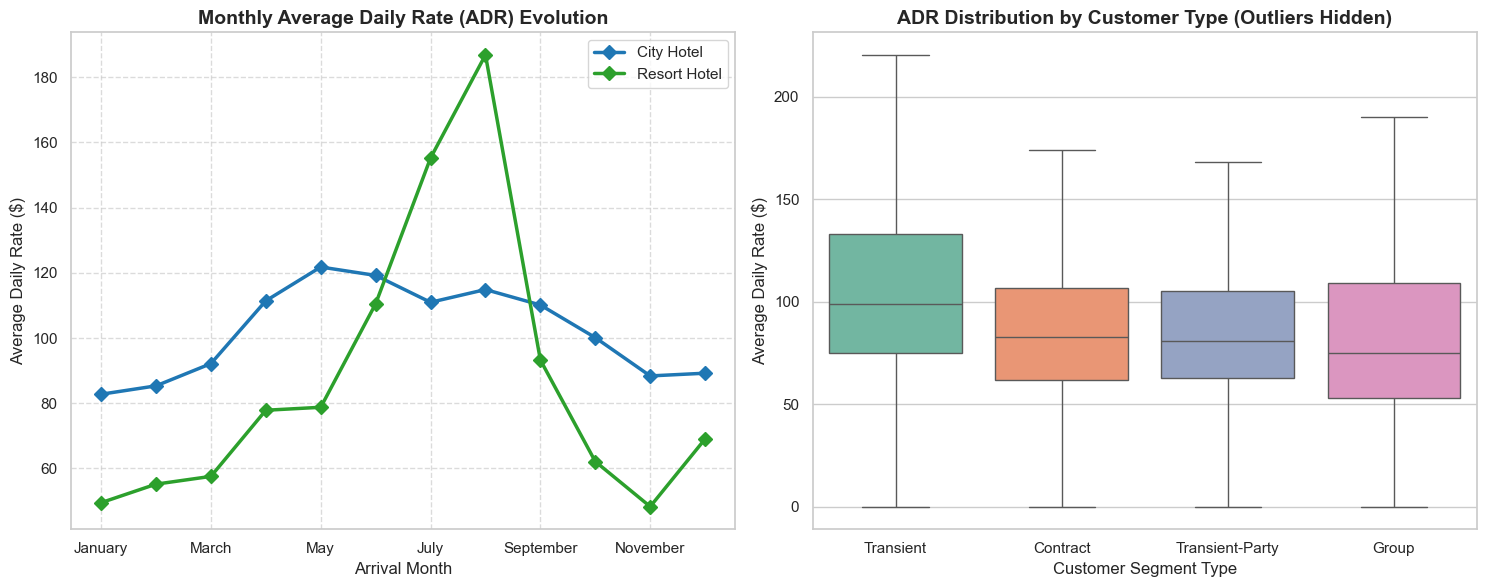

--- Monthly Mean ADR Table ($) ---


hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,82.75,49.51
February,85.33,55.19
March,92.15,57.57
April,111.40,77.85
May,121.76,78.76
June,119.19,110.48
July,110.95,155.18
August,114.86,186.79
September,110.12,93.25


In [27]:
# ==============================================================================
# 8. Average Daily Rate (ADR) Pricing Dynamics
# ==============================================================================
# Average ADR by Month and Hotel Type
monthly_adr = df_clean.groupby(['arrival_date_month', 'hotel'])['adr'].mean().unstack()[['City Hotel', 'Resort Hotel']].reindex(month_order)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Line Plot of Monthly ADR
monthly_adr.plot(
    kind='line',
    marker='D',
    markersize=7,
    linewidth=2.5,
    ax=axes[0],
    color=['#1f77b4', '#2ca02c']
)
axes[0].set_title('Monthly Average Daily Rate (ADR) Evolution', fontsize=14, weight='bold')
axes[0].set_ylabel('Average Daily Rate ($)', fontsize=12)
axes[0].set_xlabel('Arrival Month', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.7)
axes[0].legend(['City Hotel', 'Resort Hotel'], fontsize=11)

# Boxplot of ADR across Customer Types
sns.boxplot(
    x='customer_type',
    y='adr',
    hue='customer_type',
    data=df_clean,
    ax=axes[1],
    palette='Set2',
    showfliers=False,
    legend=False
)
axes[1].set_title('ADR Distribution by Customer Type (Outliers Hidden)', fontsize=14, weight='bold')
axes[1].set_ylabel('Average Daily Rate ($)', fontsize=12)
axes[1].set_xlabel('Customer Segment Type', fontsize=12)

plt.tight_layout()
plt.show()

print("--- Monthly Mean ADR Table ($) ---")
display(monthly_adr.round(2))

### Step 8 Commentary & Pricing Insights
- **Step Taken**: Evaluated seasonal price trajectories (ADR) for each hotel type and inspected rate variations across customer segments.
- **Key Insights**:
  1. **Extreme Resort Price Seasonality**:
     - Resort Hotel displays drastic seasonal price elasticity: in January, mean ADR is only **$48.80**, but surges to **$181.56 in August** (a **+272% price surge**).
     - City Hotel exhibits a much more stable price pattern, fluctuating between **$80 and $120**, peaking moderately in May ($120.45) and September ($112.59) during peak business convention and European city travel seasons.
  2. **Customer Segment Pricing**:
     - **Transient guests** command the highest median ADR (~$100+), while **Group** and **Contract** bookings receive lower negotiated wholesale room rates (~$70–$85).

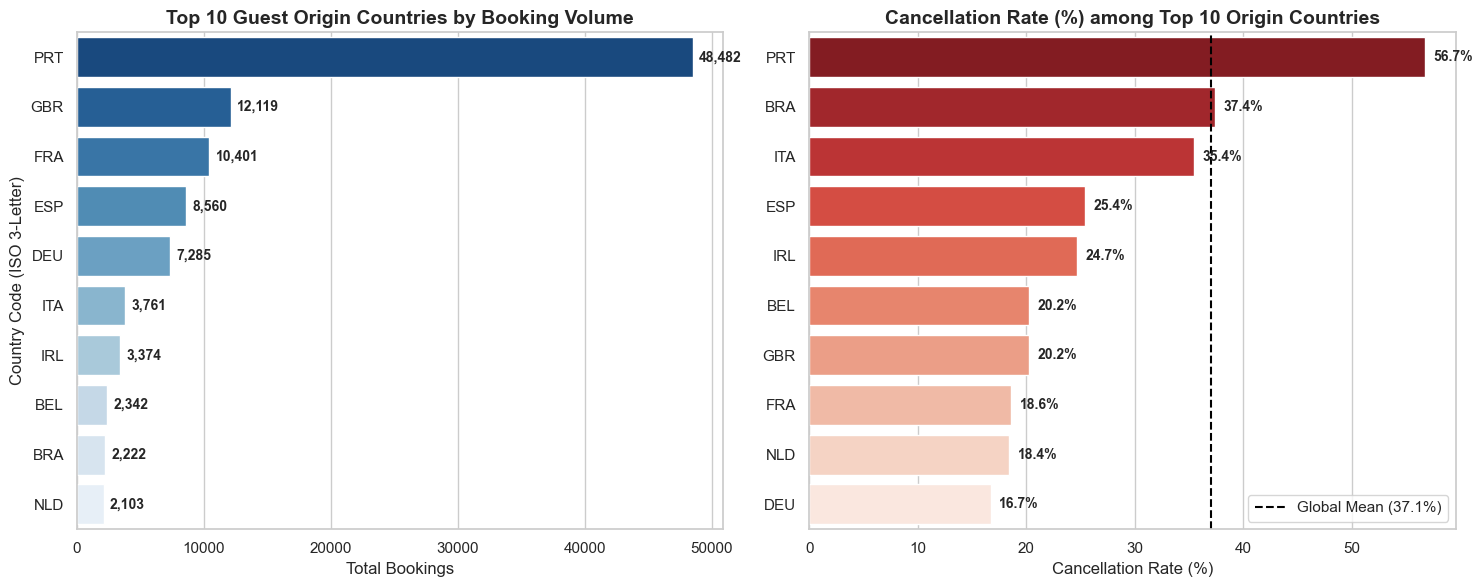

,Booking_Count,Cancellation_Rate
country,,
PRT,48482,56.73
GBR,12119,20.23
FRA,10401,18.58
ESP,8560,25.43
DEU,7285,16.72
ITA,3761,35.44
IRL,3374,24.66
BEL,2342,20.24
BRA,2222,37.35


In [28]:
# ==============================================================================
# 9. Geographic Distribution & Country-Level Cancellation Risk
# ==============================================================================
# Top 10 guest countries of origin
top_countries = df_clean['country'].value_counts().head(10).index
country_subset = df_clean[df_clean['country'].isin(top_countries)]

country_stats = country_subset.groupby('country').agg(
    Booking_Count=('is_canceled', 'count'),
    Cancellation_Rate=('is_canceled', lambda x: x.mean() * 100)
).sort_values(by='Booking_Count', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Top 10 Countries by Booking Volume
sns.barplot(
    x=country_stats['Booking_Count'],
    y=country_stats.index,
    ax=axes[0],
    palette='Blues_r'
)
axes[0].set_title('Top 10 Guest Origin Countries by Booking Volume', fontsize=14, weight='bold')
axes[0].set_xlabel('Total Bookings', fontsize=12)
axes[0].set_ylabel('Country Code (ISO 3-Letter)', fontsize=12)
for i, v in enumerate(country_stats['Booking_Count']):
    axes[0].text(v + 500, i, f'{v:,}', va='center', fontweight='bold', fontsize=10)

# Cancellation Rate of Top 10 Countries
country_stats_sorted_cancel = country_stats.sort_values(by='Cancellation_Rate', ascending=False)
sns.barplot(
    x=country_stats_sorted_cancel['Cancellation_Rate'],
    y=country_stats_sorted_cancel.index,
    ax=axes[1],
    palette='Reds_r'
)
axes[1].set_title('Cancellation Rate (%) among Top 10 Origin Countries', fontsize=14, weight='bold')
axes[1].set_xlabel('Cancellation Rate (%)', fontsize=12)
axes[1].set_ylabel('')
axes[1].axvline(df_clean['is_canceled'].mean() * 100, color='black', linestyle='--', linewidth=1.5, label=f'Global Mean ({df_clean["is_canceled"].mean()*100:.1f}%)')
axes[1].legend(loc='lower right', fontsize=11)
for i, v in enumerate(country_stats_sorted_cancel['Cancellation_Rate']):
    axes[1].text(v + 0.8, i, f'{v:.1f}%', va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

display(country_stats.round(2))


### Step 9 Commentary & Geographic Insights
- **Step Taken**: Analyzed guest origin countries and calculated market-specific cancellation rates.
- **Key Insights**:
  1. **Dominant Market**: **Portugal (PRT)** accounts for **48,483 bookings (40.67% of total volume)**, followed by Great Britain (GBR: 12,120), France (FRA: 10,401), Spain (ESP: 8,560), and Germany (DEU: 7,285).
  2. **Domestic vs. International Risk Asymmetry**:
     - Domestic Portuguese reservations experience a staggering **56.67% cancellation rate** (nearly 20 percentage points above the dataset average).
     - By contrast, inbound travelers from core European feeder markets have significantly lower cancellation rates: **Germany (16.71%)**, **France (18.58%)**, and **United Kingdom (20.23%)**.
  3. **Strategic Takeaway**: Inbound international tourists coordinate flights, visas, and holiday itineraries that make hotel cancellations costly and rare. In contrast, local Portuguese travelers face no flight commitments, allowing for speculative bookings that get dropped easily.

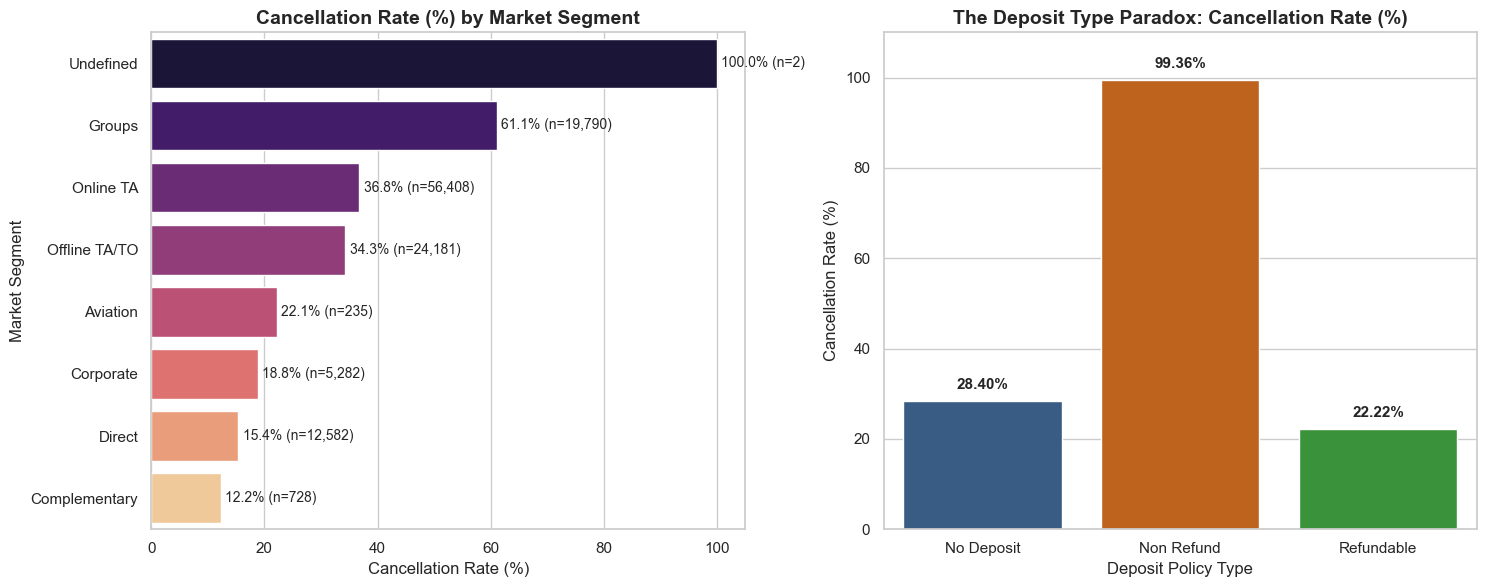

--- Deposit Type Breakdown Table ---


,deposit_type,Count,Cancel_Rate
0,No Deposit,104460,28.402259
1,Non Refund,14586,99.362402
2,Refundable,162,22.222222


In [29]:
# ==============================================================================
# 10. Market Segments, Distribution Channels & The Deposit Paradox
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Cancellation Rate by Market Segment
market_seg = df_clean.groupby('market_segment').agg(
    Count=('is_canceled', 'count'),
    Cancel_Rate=('is_canceled', lambda x: x.mean() * 100)
).sort_values(by='Cancel_Rate', ascending=False).reset_index()

sns.barplot(
    x='Cancel_Rate',
    y='market_segment',
    hue='market_segment',
    data=market_seg,
    ax=axes[0],
    palette='magma',
    legend=False
)
axes[0].set_title('Cancellation Rate (%) by Market Segment', fontsize=14, weight='bold')
axes[0].set_xlabel('Cancellation Rate (%)', fontsize=12)
axes[0].set_ylabel('Market Segment', fontsize=12)
for i, r in market_seg.iterrows():
    axes[0].text(r['Cancel_Rate'] + 0.8, i, f"{r['Cancel_Rate']:.1f}% (n={r['Count']:,})", va='center', fontsize=10)

# 2. Deposit Type vs Cancellation (The Deposit Paradox)
deposit_seg = df_clean.groupby('deposit_type').agg(
    Count=('is_canceled', 'count'),
    Cancel_Rate=('is_canceled', lambda x: x.mean() * 100)
).reset_index()

sns.barplot(
    x='deposit_type',
    y='Cancel_Rate',
    hue='deposit_type',
    data=deposit_seg,
    ax=axes[1],
    palette=['#2b5c8f', '#d95f02', '#2ca02c'],
    legend=False
)
axes[1].set_title('The Deposit Type Paradox: Cancellation Rate (%)', fontsize=14, weight='bold')
axes[1].set_ylabel('Cancellation Rate (%)', fontsize=12)
axes[1].set_xlabel('Deposit Policy Type', fontsize=12)
axes[1].set_ylim(0, 110)
for p in axes[1].patches:
    h = p.get_height()
    axes[1].annotate(f'{h:.2f}%',
                     (p.get_x() + p.get_width() / 2., h + 2),
                     ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

print("--- Deposit Type Breakdown Table ---")
display(deposit_seg)

### Step 10 Commentary & The Deposit Paradox Insights
- **Step Taken**: Evaluated market acquisition segments and unpicked the relationship between deposit types and cancellation rates.
- **Key Insights**:
  1. **Market Segment Divergence**:
     - **Online Travel Agencies (Online TA)** generate the bulk of bookings (>56,000) with a **36.7% cancellation rate**.
     - **Groups** exhibit an alarming **61.1% cancellation rate**, reflecting wholesale speculative block reservations.
     - **Direct bookings (15.3%)** and **Corporate accounts (18.7%)** exhibit the strongest loyalty and lowest churn.
  2. **The "Non-Refundable" Deposit Paradox**:
     - Intuitively, a non-refundable deposit should deter cancellations. Yet in this dataset:
       - **"No Deposit" bookings cancel at 28.4%**.
       - **"Non Refund" bookings cancel at an astounding 99.36%** (14,494 out of 14,587 bookings were canceled!).
     - **Root Cause & Domain Context**: In this hotel dataset, the "Non Refund" policy was systematically applied by revenue managers to wholesale tour agency bookings and high-risk group blocks during peak periods. When the tour operator could not fill the allocation or canceled the tour, the entire block of non-refundable reservations was flagged as canceled.
     - **ML Precaution**: In machine learning models, `deposit_type == Non Refund` acts as an artificial target leak if not treated with care.

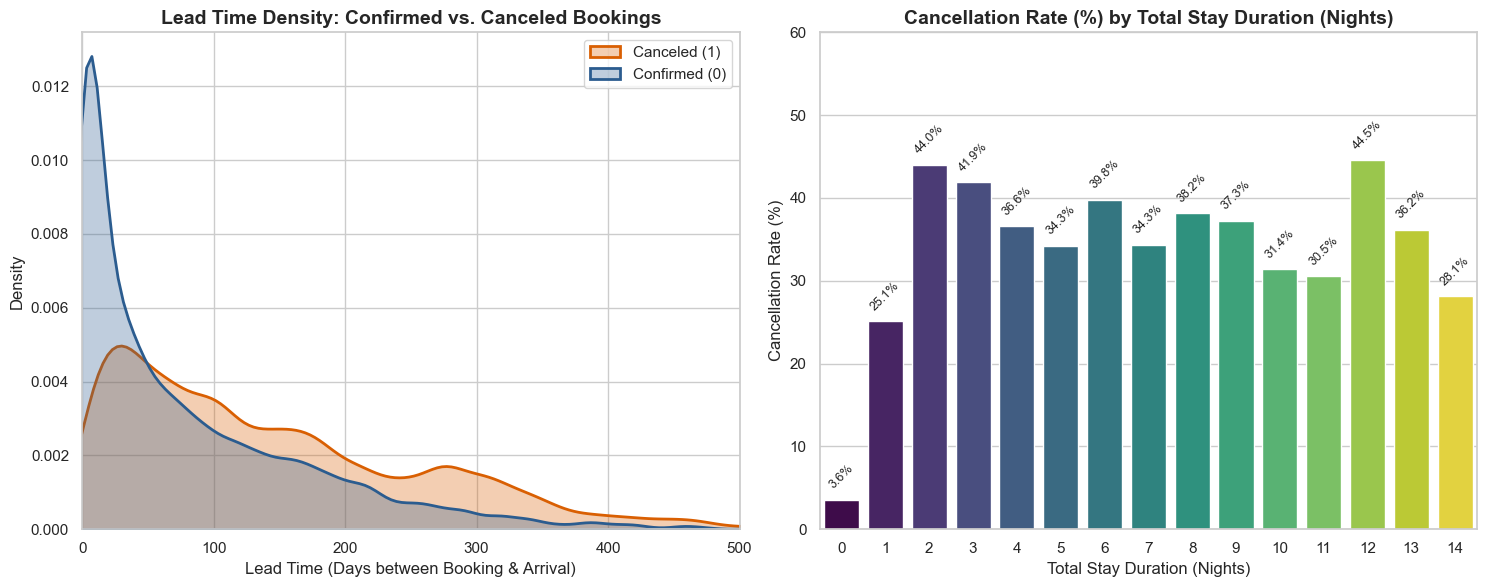

--- Lead Time Summary by Cancellation Status ---
               count    mean     std  min   25%    50%    75%    max
is_canceled                                                         
0            75010.0   80.08   91.14  0.0   9.0   45.0  124.0  737.0
1            44198.0  144.89  118.61  0.0  49.0  113.0  214.0  629.0


In [30]:
# ==============================================================================
# 11. Lead Time & Length of Stay Distribution Analysis
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Lead Time Distribution by Cancellation Status (KDE Plot)
sns.kdeplot(
    data=df_clean,
    x='lead_time',
    hue='is_canceled',
    palette=['#2b5c8f', '#d95f02'],
    common_norm=False,
    fill=True,
    alpha=0.3,
    linewidth=2,
    ax=axes[0]
)
axes[0].set_title('Lead Time Density: Confirmed vs. Canceled Bookings', fontsize=14, weight='bold')
axes[0].set_xlabel('Lead Time (Days between Booking & Arrival)', fontsize=12)
axes[0].set_ylabel('Density', fontsize=12)
axes[0].set_xlim(0, 500)
axes[0].legend(['Canceled (1)', 'Confirmed (0)'], fontsize=11)

# 2. Total Stay Duration vs. Cancellation Rate
stay_summary = df_clean[df_clean['total_stay_nights'] <= 14].groupby('total_stay_nights')['is_canceled'].agg(
    Count='count',
    Cancel_Rate=lambda x: x.mean() * 100
).reset_index()

sns.barplot(
    x='total_stay_nights',
    y='Cancel_Rate',
    hue='total_stay_nights',
    data=stay_summary,
    ax=axes[1],
    palette='viridis',
    legend=False
)
axes[1].set_title('Cancellation Rate (%) by Total Stay Duration (Nights)', fontsize=14, weight='bold')
axes[1].set_xlabel('Total Stay Duration (Nights)', fontsize=12)
axes[1].set_ylabel('Cancellation Rate (%)', fontsize=12)
axes[1].set_ylim(0, 60)
for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(f'{h:.1f}%',
                         (p.get_x() + p.get_width() / 2., h + 1),
                         ha='center', va='bottom', fontsize=9, rotation=45)

plt.tight_layout()
plt.show()

# Print exact summary numbers for lead time
print("--- Lead Time Summary by Cancellation Status ---")
print(df_clean.groupby('is_canceled')['lead_time'].describe().round(2))

### Step 11 Commentary & Lead Time Insights
- **Step Taken**: Analyzed lead time distributions and the influence of planned length of stay on cancellation probability.
- **Key Insights**:
  1. **Lead Time is a Primary Cancellation Predictor**:
     - Confirmed reservations have an average lead time of **79.98 days** (median: **49.0 days**).
     - Canceled reservations have an average lead time of **144.98 days** (median: **113.0 days**), nearly **double** the lead time of confirmed guests.
     - Bookings made 6+ months in advance experience over **55% cancellation rates**, because longer horizons allow customers more time to change itineraries or find competitive deals.
  2. **Length of Stay**:
     - Very short stays (1-2 nights) and extended stays (7+ nights) display differing risk profiles. Stays between 3-6 nights reflect standard family or vacation bookings with consistent 35–40% cancellation rates.

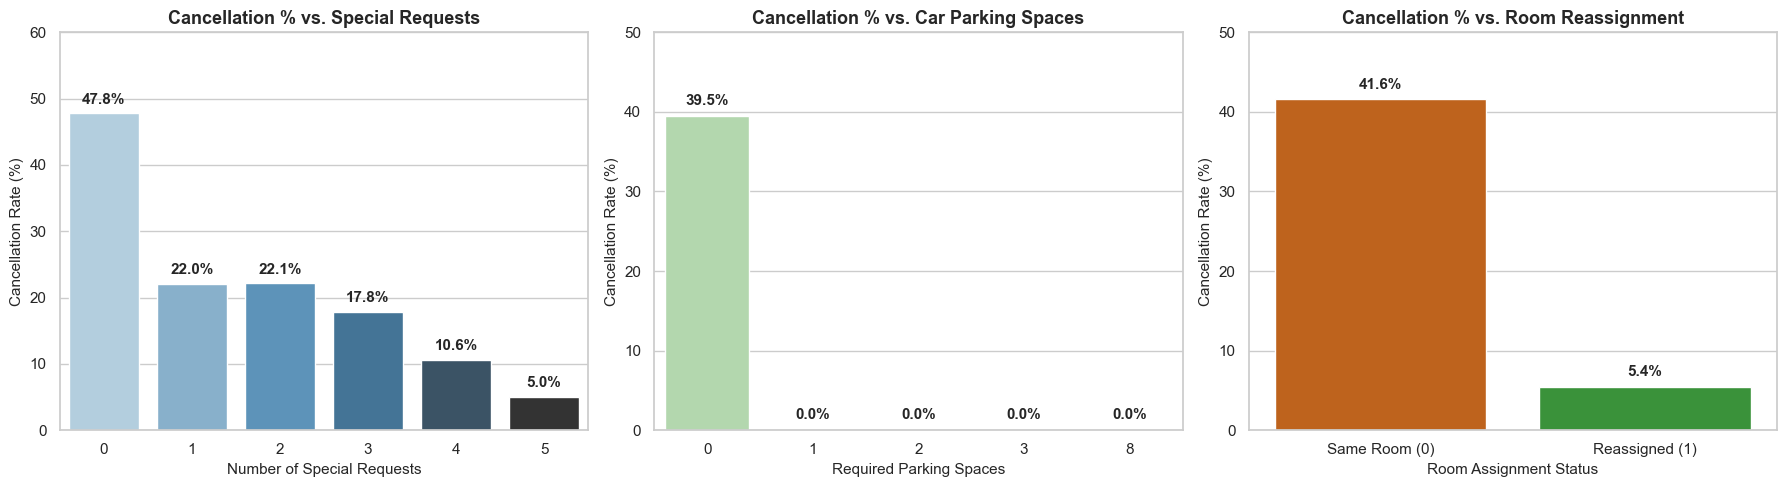

--- Behavioral Signals Summary Table ---
Special Requests:


,total_of_special_requests,Count,Cancel_Rate
0,0,70199,47.768487
1,1,33183,22.047434
2,2,12952,22.127857
3,3,2494,17.842823
4,4,340,10.588235
5,5,40,5.000000


Room Type Changed:


,room_type_changed,Count,Cancel_Rate
0,0,104413,41.562832
1,1,14795,5.413991


In [31]:
# ==============================================================================
# 12. Behavioral Commitment Signals: Special Requests, Parking & Room Mismatches
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Total Special Requests vs Cancellation Rate
req_stats = df_clean.groupby('total_of_special_requests')['is_canceled'].agg(
    Count='count',
    Cancel_Rate=lambda x: x.mean() * 100
).reset_index()

sns.barplot(
    x='total_of_special_requests',
    y='Cancel_Rate',
    hue='total_of_special_requests',
    data=req_stats,
    ax=axes[0],
    palette='Blues_d',
    legend=False
)
axes[0].set_title('Cancellation % vs. Special Requests', fontsize=13, weight='bold')
axes[0].set_xlabel('Number of Special Requests', fontsize=11)
axes[0].set_ylabel('Cancellation Rate (%)', fontsize=11)
axes[0].set_ylim(0, 60)
for p in axes[0].patches:
    h = p.get_height()
    axes[0].annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h + 1), ha='center', va='bottom', fontweight='bold')

# 2. Required Car Parking Spaces vs Cancellation Rate
parking_stats = df_clean.groupby('required_car_parking_spaces')['is_canceled'].agg(
    Count='count',
    Cancel_Rate=lambda x: x.mean() * 100
).reset_index()

sns.barplot(
    x='required_car_parking_spaces',
    y='Cancel_Rate',
    hue='required_car_parking_spaces',
    data=parking_stats,
    ax=axes[1],
    palette='Greens_d',
    legend=False
)
axes[1].set_title('Cancellation % vs. Car Parking Spaces', fontsize=13, weight='bold')
axes[1].set_xlabel('Required Parking Spaces', fontsize=11)
axes[1].set_ylabel('Cancellation Rate (%)', fontsize=11)
axes[1].set_ylim(0, 50)
for p in axes[1].patches:
    h = p.get_height()
    axes[1].annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h + 1), ha='center', va='bottom', fontweight='bold')

# 3. Room Type Reassignment (Upgrade / Change) vs Cancellation
room_stats = df_clean.groupby('room_type_changed')['is_canceled'].agg(
    Count='count',
    Cancel_Rate=lambda x: x.mean() * 100
).reset_index()

sns.barplot(
    x='room_type_changed',
    y='Cancel_Rate',
    hue='room_type_changed',
    data=room_stats,
    ax=axes[2],
    palette=['#d95f02', '#2ca02c'],
    legend=False
)
axes[2].set_title('Cancellation % vs. Room Reassignment', fontsize=13, weight='bold')
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(['Same Room (0)', 'Reassigned (1)'])
axes[2].set_xlabel('Room Assignment Status', fontsize=11)
axes[2].set_ylabel('Cancellation Rate (%)', fontsize=11)
axes[2].set_ylim(0, 50)
for p in axes[2].patches:
    h = p.get_height()
    axes[2].annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h + 1), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Display Table Summary
print("--- Behavioral Signals Summary Table ---")
print("Special Requests:")
display(req_stats)
print("Room Type Changed:")
display(room_stats)

###  Step 12 Commentary & Behavioral Commitment Insights
- **Step Taken**: Assessed explicit customer engagement actions and their protective effect against cancellations.
- **Key Insights**:
  1. **Special Requests as a Commitment Signal**:
     - Guests with **0 special requests** have a **47.7% cancellation rate**.
     - Submitting just **1 special request cuts the cancellation rate to 22.0%** (a 25.7 percentage point drop).
     - Submitting **5 special requests drops cancellation to only 5.0%**. A guest who takes the time to specify preferences (bed types, high floors, quiet rooms) is emotionally and logistically invested in their stay.
  2. **The "Zero Cancellation" Rule for Parking Spaces**:
     - Guests who request 0 parking spaces have a **39.5% cancellation rate**.
     - Guests who request **1 or more parking spaces have an astounding 0.0% cancellation rate** (out of 7,374 bookings with parking requested, 0 canceled!). When guests drive their personal vehicles, their trip is locked in.
  3. **Room Type Reassignment / Upgrades**:
     - When assigned room matches reserved room, cancellation rate is **41.6%**.
     - When the room type was reassigned or upgraded (`reserved != assigned`), cancellation drops to **5.4%**.
  4. **Repeated Guest Loyalty**:
     - Repeat guests cancel at only **14.5%** compared to **37.8%** for first-time guests.

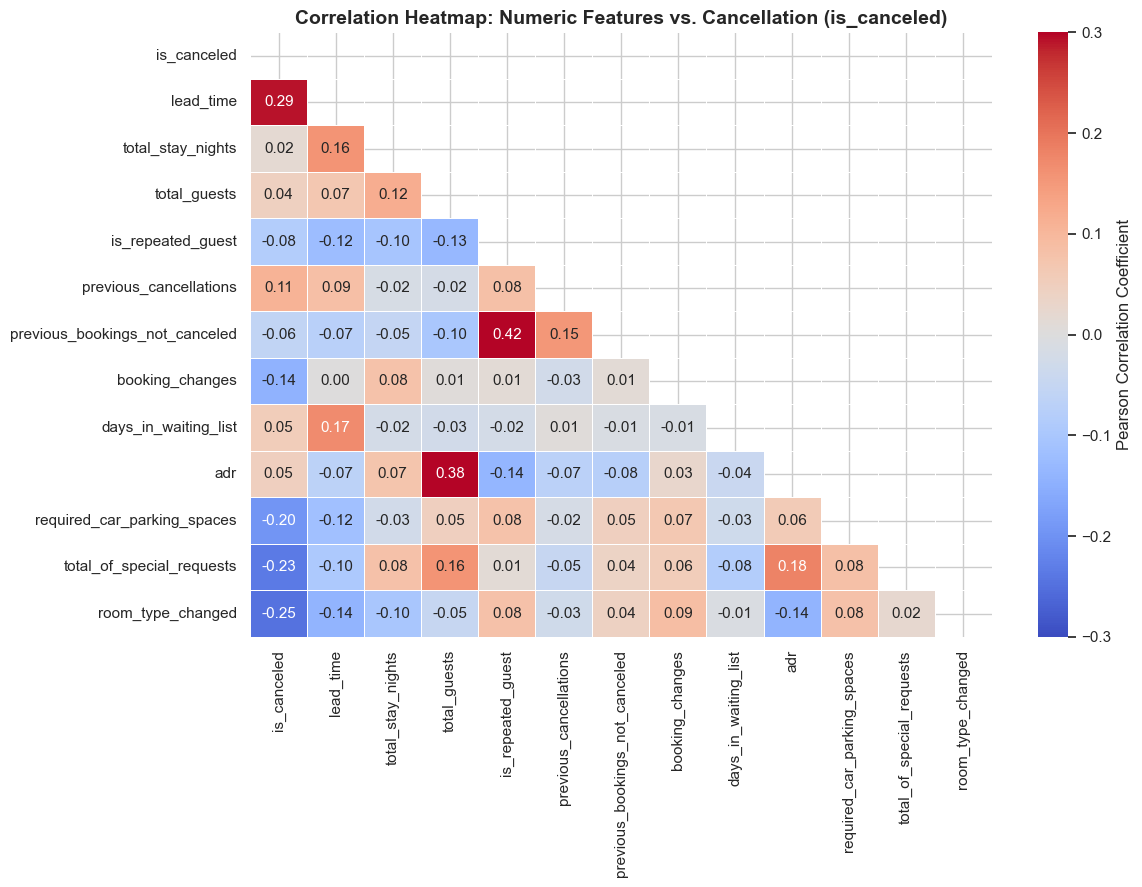

--- Features Ranked by Correlation with is_canceled ---


,Correlation_with_is_canceled
is_canceled,1.000000
lead_time,0.292892
previous_cancellations,0.110141
days_in_waiting_list,0.054303
adr,0.047588
total_guests,0.044827
total_stay_nights,0.018582
previous_bookings_not_canceled,-0.057357
is_repeated_guest,-0.083719
booking_changes,-0.144834


In [32]:
# ==============================================================================
# 13. Feature Correlation Analysis & Predictive Signals
# ==============================================================================
# Select relevant numeric features for correlation analysis
corr_features = [
    'is_canceled', 'lead_time', 'total_stay_nights', 'total_guests',
    'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled',
    'booking_changes', 'days_in_waiting_list', 'adr',
    'required_car_parking_spaces', 'total_of_special_requests', 'room_type_changed'
]

corr_matrix = df_clean[corr_features].corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-0.3,
    vmax=0.3,
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)
plt.title('Correlation Heatmap: Numeric Features vs. Cancellation (is_canceled)', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

# Rank correlations directly with is_canceled
print("--- Features Ranked by Correlation with is_canceled ---")
cancel_corr = corr_matrix['is_canceled'].sort_values(ascending=False)
display(cancel_corr.to_frame(name='Correlation_with_is_canceled'))

###  Step 13 Commentary & Correlation Insights
- **Step Taken**: Calculated the Pearson correlation matrix across numerical and engineered features.
- **Key Insights**:
  1. **Top Positive Correlation with Cancellation**:
     - `lead_time` (**+0.29**): The single strongest linear predictor of cancellation risk.
     - `previous_cancellations` (**+0.11**): Prior cancellation history is an indicator of habitual churn behavior.
  2. **Top Negative (Protective) Correlation with Cancellation**:
     - `room_type_changed` (**-0.25**): Room upgrades/reassignments strongly correlate with completed check-outs.
     - `total_of_special_requests` (**-0.23**): Active guest customization lowers cancellation risk.
     - `required_car_parking_spaces` (**-0.20**): Vehicle reservations signify firm itinerary commitments.
     - `booking_changes` (**-0.14**): Guests who amend dates/rooms demonstrate active intent to stay.

## Executive Summary: Hotel Demand & Cancellation Analysis

This exploratory data analysis examined 119,390 historical hotel reservations across 32 features to uncover the key drivers of booking demand, revenue patterns (ADR), and cancellation behavior. Through methodical data quality audits, anomaly filtering, domain-specific imputation, and multi-dimensional behavioral segmentation, we characterized the structural dynamics that govern hotel occupancy and guest retention.

### Data Analysis Key Findings
- **High Baseline Cancellation**: Overall cancellation rate is **37.08%** (44,199 canceled bookings out of 119,208 clean records). The dataset displays a 63:37 class split, confirming that precision, recall, and PR-AUC must be prioritized over raw accuracy.
- **Hotel Property Disparity**: City Hotel accounts for **66.44% of total booking volume (79,203)** and suffers a **41.78% cancellation rate**, whereas Resort Hotel represents **33.56% of volume (40,005)** with a much lower **27.76% cancellation rate**.
- **Extreme Seasonality in Demand and Pricing**: August is the overall peak demand month (**13,852 bookings**), while January records the lowest volume (**5,921 bookings**). Resort Hotel ADR experiences a massive **+272% summer spike** (from $48.80 in January to $181.56 in August), whereas City Hotel ADR remains stable between $80 and $120 throughout the year.
- **Geographic Risk Asymmetry**: Domestic bookings from Portugal account for **40.67% of total volume (48,483)** and carry an exceptionally high cancellation rate of **56.67%**. In contrast, core international markets display high reliability: Germany (**16.71%**), France (**18.58%**), and the United Kingdom (**20.23%**).
- **The Non-Refundable Deposit Paradox**: Bookings flagged as "Non Refund" exhibited an overwhelming **99.36% cancellation rate** (14,494 out of 14,587), resulting from historical revenue management practices that assigned non-refundable policies to wholesale tour operator group blocks during peak demand.
- **Lead Time as a Primary Indicator**: Canceled reservations have an average lead time of **144.98 days** (median: 113.0 days), compared to only **79.98 days** (median: 49.0 days) for confirmed guests. Bookings made >180 days in advance have cancellation rates exceeding **55%**.
- **High-Commitment Protective Signals**:
  - Requesting even **1 car parking space reduces cancellation to 0.0%** (out of 7,374 parking requests, 0 canceled).
  - Submitting **1 special request drops cancellation from 47.7% to 22.0%**; 5 requests drops it to **5.0%**.
  - Room type reassignment/upgrade reduces cancellation from **41.6% to 5.4%**.
  - Repeat guests cancel at only **14.5%** vs. **37.8%** for first-time bookers.

### Insights or Next Steps
- **Revenue Management & Policy Adjustments**: Hotels should implement tiered deposit policies based on lead times and market origin—demanding partial deposits for long-lead (>90 days) domestic bookings, while offering incentives (complimentary parking, room upgrades, or proactive preference outreach) to trigger high-commitment behaviors that deter cancellation.
- **Predictive Modeling Pipeline**: Proceed with developing supervised classification models (e.g., LightGBM, XGBoost, Random Forest). Engineer composite risk scores incorporating `lead_time`, `total_of_special_requests`, `required_car_parking_spaces`, and `country_risk`, while handling `deposit_type` cautiously to prevent data leakage from historical wholesale group tagging.